In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 


In [75]:
df=pd.read_csv("churn_data.csv")

In [76]:
df.head(5)

,customerID,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,1,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,34,Yes,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,2,Yes,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,45,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,2,Yes,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [77]:
print("="*5,"summary","="*5)
df.info()

===== summary =====
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   tenure            7043 non-null   int64  
 2   PhoneService      7043 non-null   str    
 3   Contract          7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
 8   Churn             7043 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 863.4 KB


In [78]:
df.describe()

,tenure,MonthlyCharges
count,7043.000000,7043.000000
mean,32.371149,64.761692
std,24.559481,30.090047
min,0.000000,18.250000
25%,9.000000,35.500000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.750000


In [79]:
df.describe(include='object')

C:\Users\Tibya\AppData\Local\Temp\ipykernel_2140\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,customerID,PhoneService,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,3,2,4,6531,2
top,7590-VHVEG,Yes,Month-to-month,Yes,Electronic check,20.2,No
freq,1,6361,3875,4171,2365,11,5174


In [80]:
print("="*10,"null values","="*10)
print(df.isnull().sum())

========== null values ==========
customerID          0
tenure              0
PhoneService        0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [81]:
print("="*10,"duplicates","="*10)
print(df.duplicated().sum())

========== duplicates ==========
0


In [82]:
df.columns.tolist()

['customerID',
 'tenure',
 'PhoneService',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [83]:
df.columns=(
    df.columns
    .str.lower()
    .str.strip()
)

In [84]:
df.columns.tolist()

['customerid',
 'tenure',
 'phoneservice',
 'contract',
 'paperlessbilling',
 'paymentmethod',
 'monthlycharges',
 'totalcharges',
 'churn']

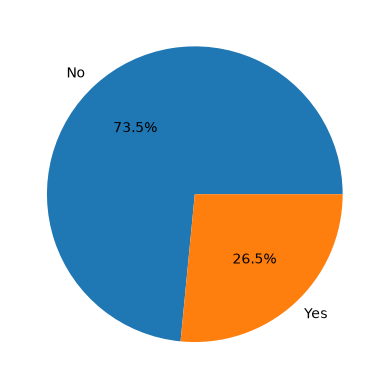

In [85]:
c=df['churn'].value_counts()
plt.pie(c,labels=['No','Yes'],autopct="%1.1f%%")

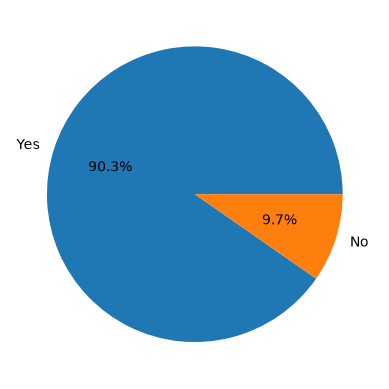

In [86]:
g=df['phoneservice'].value_counts()
plt.pie(g, labels=['Yes','No'],autopct="%1.1f%%")

In [87]:
df['contract'].value_counts()

contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

C:\Users\Tibya\AppData\Local\Temp\ipykernel_2140\2961006666.py:1: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:red'` for the same effect.

  sns.countplot(data=df,x="contract",hue='churn',color='red')


<Axes: xlabel='contract', ylabel='count'>

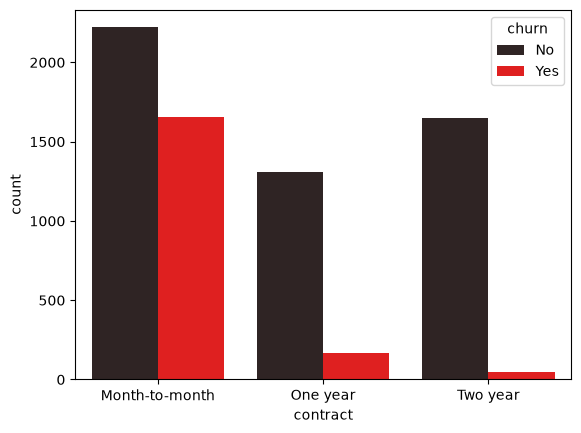

In [88]:
sns.countplot(data=df,x="contract",hue='churn',color='red')

In [89]:
df['contract']=df['contract'].replace({
    "Month-to-month":"month",
    "One year contract":"year",
    "Two year":"two_year"
})

In [90]:
df=pd.get_dummies(data=df,columns=['contract'],drop_first=True,dtype=int)

In [91]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['churn']=le.fit_transform(df['churn'])
df['phoneservice']=le.fit_transform(df['phoneservice'])

In [92]:
df.select_dtypes(exclude='object')

,tenure,phoneservice,monthlycharges,churn,contract_month,contract_two_year
0,1,0,29.85,0,1,0
1,34,1,56.95,0,0,0
2,2,1,53.85,1,1,0
3,45,0,42.30,0,0,0
4,2,1,70.70,1,1,0
...,...,...,...,...,...,...
7038,24,1,84.80,0,0,0
7039,72,1,103.20,0,0,0
7040,11,0,29.60,0,1,0
7041,4,1,74.40,1,1,0


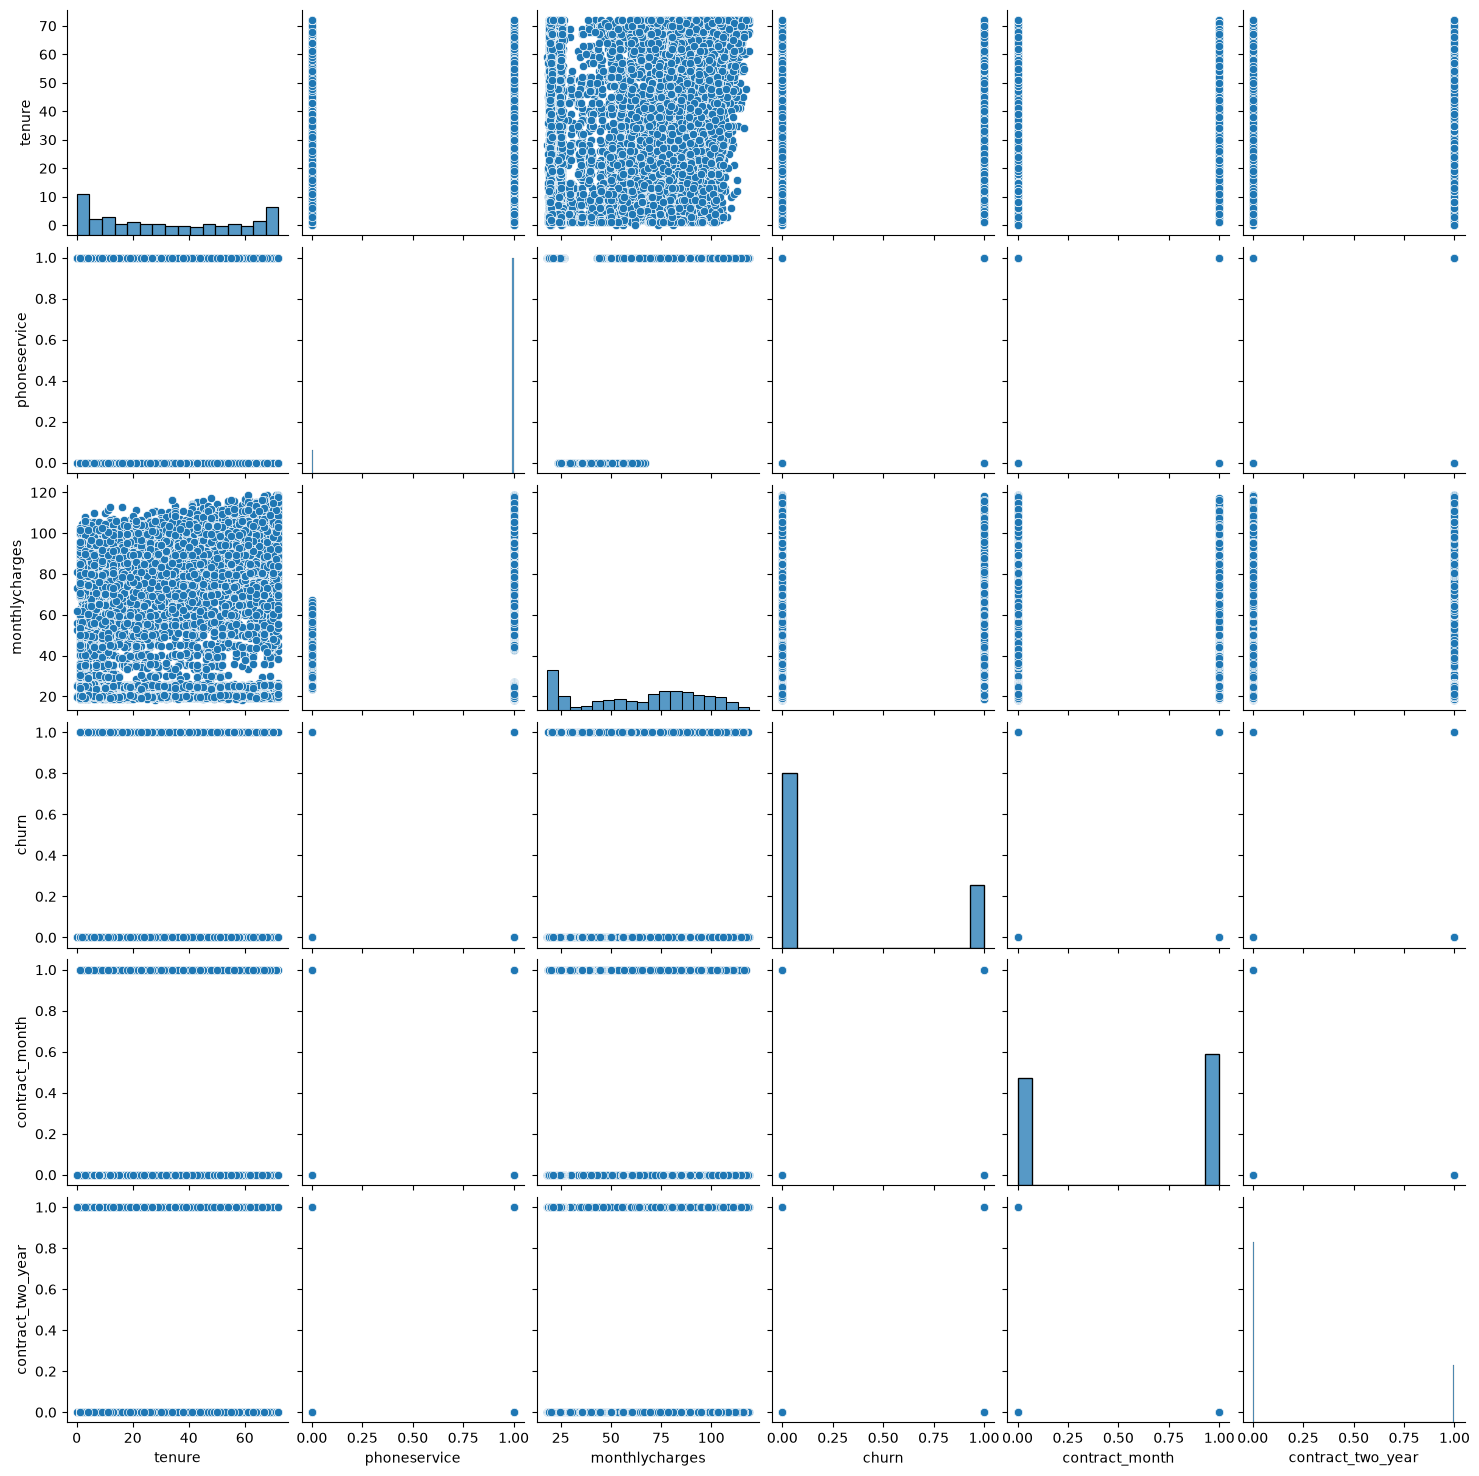

In [93]:
col=df.select_dtypes(exclude='object')
sns.pairplot(col)

<Axes: >

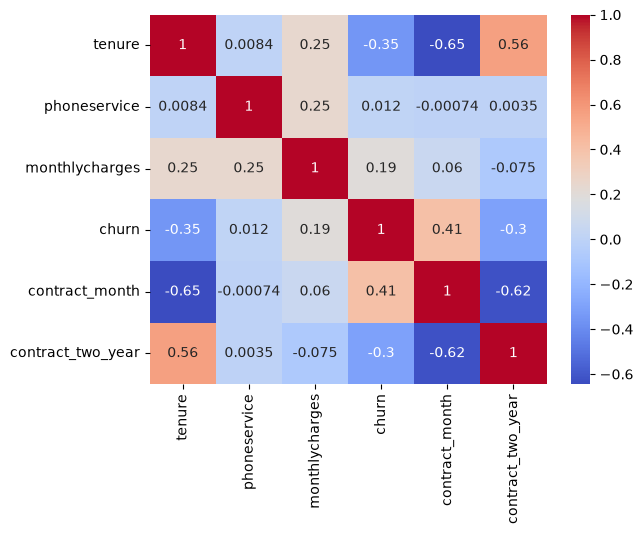

In [94]:
corr=df.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm')

In [95]:
df['two_year_add']=df['contract_two_year']**2*(df['churn'])
df['cutomer_tenure']=df['tenure']**2*(df['contract_two_year'])

C:\Users\Tibya\AppData\Local\Temp\ipykernel_2140\1307569394.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:green'` for the same effect.

  sns.countplot(data=df,x='tenure',hue='phoneservice',color='green')


<Axes: xlabel='tenure', ylabel='count'>

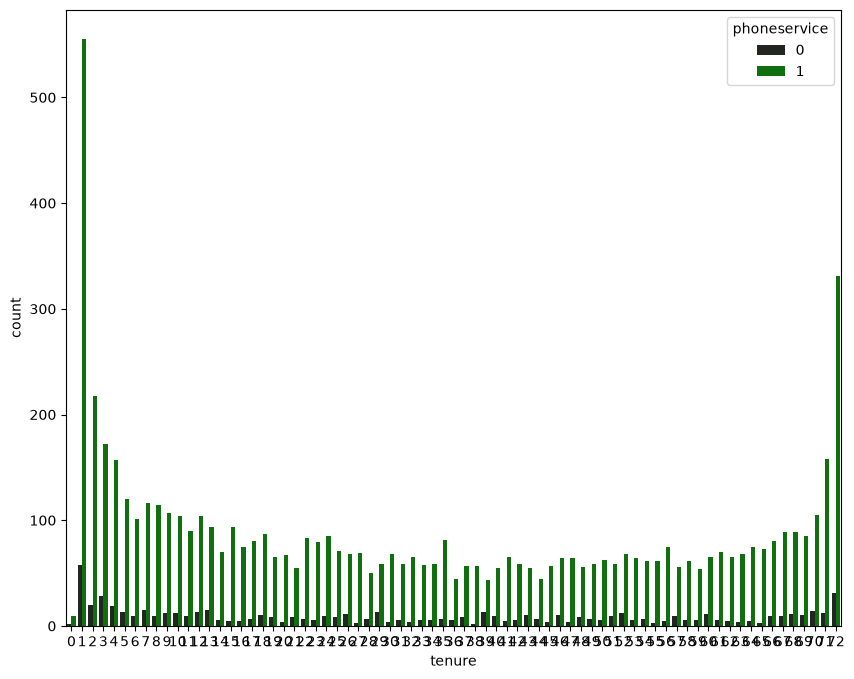

In [96]:
plt.figure(figsize=(10,8))
sns.countplot(data=df,x='tenure',hue='phoneservice',color='green')

In [97]:
df.select_dtypes(exclude='number')

,customerid,paperlessbilling,paymentmethod,totalcharges
0,7590-VHVEG,Yes,Electronic check,29.85
1,5575-GNVDE,No,Mailed check,1889.5
2,3668-QPYBK,Yes,Mailed check,108.15
3,7795-CFOCW,No,Bank transfer (automatic),1840.75
4,9237-HQITU,Yes,Electronic check,151.65
...,...,...,...,...
7038,6840-RESVB,Yes,Mailed check,1990.5
7039,2234-XADUH,Yes,Credit card (automatic),7362.9
7040,4801-JZAZL,Yes,Electronic check,346.45
7041,8361-LTMKD,Yes,Mailed check,306.6


In [98]:
df['paymentmethod'].value_counts()

paymentmethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [114]:
df['paymentmethod']=le.fit_transform(df['paymentmethod'])
df['paperlessbilling']=le.fit_transform(df['paperlessbilling'])

In [115]:
df.columns

Index(['customerid', 'tenure', 'phoneservice', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn',
       'contract_month', 'contract_two_year', 'two_year_add', 'cutomer_tenure',
       'total_tenur'],
      dtype='str')

In [116]:
df_clean=df.drop(columns=['customerid'],axis='column')

<Axes: >

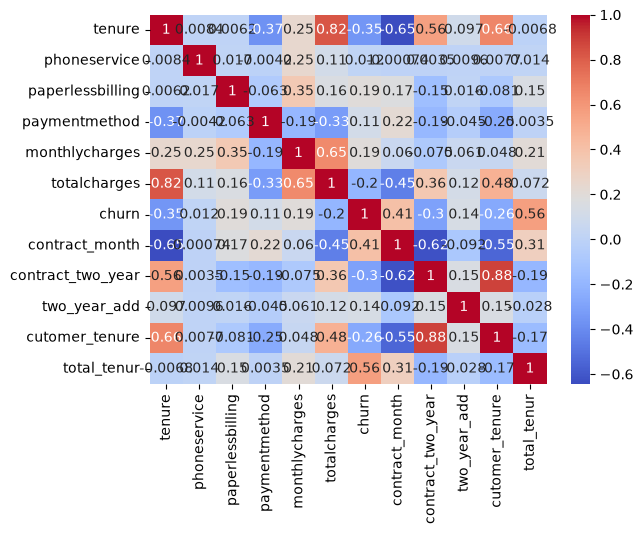

In [117]:
plt.Figure(figsize=(16,12))
corr=df_clean.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='coolwarm')

In [118]:
df['total_tenur']=df['tenure']*df['contract_month']*df['churn']

In [119]:
df['totalcharges']=pd.to_numeric(df['totalcharges'],errors='coerce')

In [120]:
df['totalcharges'].isnull().sum()
df['totalcharges']=df['totalcharges'].fillna(df['totalcharges'].mean())

In [108]:
df['totalcharges'].isnull().sum()

np.int64(0)

In [121]:
df_clean.select_dtypes(include='object')

""
0
1
2
3
4
...
7038
7039
7040
7041


In [122]:
df_clean.head(4)

,tenure,phoneservice,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn,contract_month,contract_two_year,two_year_add,cutomer_tenure,total_tenur
0,1,0,1,2,29.85,29.85,0,1,0,0,0,0
1,34,1,0,3,56.95,1889.50,0,0,0,0,0,0
2,2,1,1,3,53.85,108.15,1,1,0,0,0,2
3,45,0,0,0,42.30,1840.75,0,0,0,0,0,0


In [123]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split


In [124]:
x=df_clean.drop(columns=['churn'],axis='column')
y=df_clean['churn']

In [125]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [126]:
x_train.select_dtypes(include='object')

""
2142
1623
6074
1362
6754
...
3772
5191
5226
5390


In [127]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [128]:
log=LogisticRegression(max_iter=2000,class_weight='balanced',C=0.1,solver='lbfgs')
log.fit(x_train_scaled,y_train)
y_pred=log.predict(x_test_scaled)

In [129]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [130]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.9460610361958836
precision_score:  0.8778625954198473
recall_score:  0.9249329758713136
f1_score:  0.9007832898172323


In [131]:
random=RandomForestClassifier(n_estimators=100,random_state=42)
random.fit(x_train_scaled,y_train)
y_pred=random.predict(x_test_scaled)

In [132]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.9801277501774308
precision_score:  0.9859154929577465
recall_score:  0.938337801608579
f1_score:  0.9615384615384616


In [133]:
ada=AdaBoostClassifier(n_estimators=100,random_state=42)
ada.fit(x_train_scaled,y_train)
y_pred=ada.predict(x_test_scaled)

In [134]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.9836763662171752
precision_score:  1.0
recall_score:  0.938337801608579
f1_score:  0.9681881051175657


In [135]:
bag=BaggingClassifier(n_estimators=100,max_samples=2)
bag.fit(x_train_scaled,y_train)
y_pred=ada.predict(x_test_scaled)

In [136]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.9836763662171752
precision_score:  1.0
recall_score:  0.938337801608579
f1_score:  0.9681881051175657


In [137]:
tree=DecisionTreeClassifier(max_depth=2,min_samples_split=10)
tree.fit(x_train_scaled,y_train)
y_pred=tree.predict(x_test_scaled)

In [138]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.9836763662171752
precision_score:  1.0
recall_score:  0.938337801608579
f1_score:  0.9681881051175657


In [139]:
knn=KNeighborsClassifier()
knn.fit(x_train_scaled,y_train)
y_pred=knn.predict(x_test_scaled)

In [140]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.9673527324343506
precision_score:  0.947945205479452
recall_score:  0.9276139410187667
f1_score:  0.9376693766937669


In [ ]:
b=MultinomialNB()
b.fit(x_train,y_train)
y_pred=b.predict(x_test)

In [ ]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.49751596877217885
precision_score:  0.34213006597549483
recall_score:  0.9731903485254692
f1_score:  0.5062761506276151


In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid={
    'criterion':['gini','entropy'],
    'max_depth':[3,5,7,10,15,None],
    'min_samples_split':[2,5,10],
     'min_samples_leaf':[1,2,4]
  

}
grid_search=GridSearchCV(estimator=tree,param_grid=param_grid,cv=5,scoring='f1',n_jobs=-1)
grid_search.fit(x_train_scaled,y_train)
print(grid_search.best_params_)

{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 4, 'min_samples_split': 2}


In [141]:
tree=DecisionTreeClassifier(criterion='gini',max_depth=7,min_samples_leaf=4,min_samples_split=2)
tree.fit(x_train_scaled,y_train)
y_pred=tree.predict(x_test_scaled)

In [142]:
print("accuracy_score: ",accuracy_score(y_test,y_pred))
print("precision_score: ",precision_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))

accuracy_score:  0.9829666430092264
precision_score:  0.9971509971509972
recall_score:  0.938337801608579
f1_score:  0.9668508287292817


In [144]:
import pickle
pickle.dump(tree,open('model.pkl','wb'))